In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")
warnings.filterwarnings("ignore",category=DeprecationWarning)
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import learning_curve
from tensorflow.keras.layers import GRU, Dense, Dropout, BatchNormalization


In [3]:
vgg16_features = pd.read_csv('/Users/aasnamanjakkal/Desktop/ExtractedFeatures_VGG16_2.csv')
mfcc_features = pd.read_csv('/Users/aasnamanjakkal/Desktop/data/audio_features_mfcc.csv')

In [5]:
vgg16_data = vgg16_features.drop(columns=['Emotions'])
vgg16_labels = vgg16_features['Emotions']
mfcc_data = mfcc_features.drop(columns=['Emotions'])
mfcc_labels = mfcc_features['Emotions']

In [7]:
# Check the number of samples in both datasets before scaling
print("VGG16 Data Shape:", vgg16_data.shape)
print("MFCC Data Shape:", mfcc_data.shape)

VGG16 Data Shape: (38721, 512)
MFCC Data Shape: (1440, 13)


In [9]:
if 'ID' in vgg16_features.columns and 'ID' in mfcc_features.columns:
    # Merge on the 'ID' column
    vgg16_features = vgg16_features.set_index('ID')
    mfcc_features = mfcc_features.set_index('ID')
    combined_data = vgg16_features.join(mfcc_features, how='inner', lsuffix='_vgg', rsuffix='_mfcc')
    
    # Separate features and labels after merging
    vgg16_data = combined_data.filter(regex='_vgg')
    mfcc_data = combined_data.filter(regex='_mfcc')
    vgg16_labels = combined_data['Emotions']  # assuming the 'Emotions' label is in VGG16 data

else:
    print("No matching ID column found for alignment. Please ensure both datasets have the same samples.")

# Check the shapes again after merging to ensure they match
print("Aligned VGG16 Data Shape:", vgg16_data.shape)
print("Aligned MFCC Data Shape:", mfcc_data.shape)

No matching ID column found for alignment. Please ensure both datasets have the same samples.
Aligned VGG16 Data Shape: (38721, 512)
Aligned MFCC Data Shape: (1440, 13)


In [11]:
scaler_mfcc = StandardScaler()
mfcc_data_scaled = scaler_mfcc.fit_transform(mfcc_data)
scaler = StandardScaler()
vgg16_features_scaled = scaler.fit_transform(vgg16_data)


In [13]:
from sklearn.decomposition import PCA
pca_95 = PCA(n_components=0.95)  # Retains 95% of variance
vgg16_reduced = pca_95.fit_transform(vgg16_features_scaled)
# Ensure the MFCC dataset's 'Emotions' column is dropped for feature scaling and merging
mfcc_data = mfcc_features.drop(columns=['Emotions'])

# Merge the VGG16 and MFCC datasets directly based on their indices
combined_data = pd.concat([vgg16_features, mfcc_data], axis=1)

# If 'Emotions' is the label column in VGG16 data, you can directly assign it
vgg16_labels = vgg16_features['Emotions']  # Assuming 'Emotions' is the label in the VGG16 dataset

# Now check the shape of the combined dataset
print("Combined Data Shape:", combined_data.shape)
print("Labels Shape:", vgg16_labels.shape)
combined_data.to_csv('/Users/aasnamanjakkal/Desktop/data/fused_features_PCA.csv', index= False)

Combined Data Shape: (38721, 526)
Labels Shape: (38721,)


In [14]:
features = combined_data.drop(columns=['Emotions'])
labels = vgg16_labels

# Now scale the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Verify the shape of the scaled features
print("Scaled Features Shape:", features_scaled.shape)

Scaled Features Shape: (38721, 525)


In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    features_scaled, labels, test_size=0.2, stratify=labels, random_state=42
)
train_df = pd.concat([
    pd.Series(y_train, name='Emotions').reset_index(drop=True),
    pd.DataFrame(X_train).reset_index(drop=True)
], axis=1)

test_df = pd.concat([
    pd.Series(y_test, name='Emotions').reset_index(drop=True),
    pd.DataFrame(X_test).reset_index(drop=True)
], axis=1)

# Save the train and test data
train_df.to_csv('/Users/aasnamanjakkal/Desktop/data/train_fused_features_PCA.csv', index=False)
test_df.to_csv('/Users/aasnamanjakkal/Desktop/data/test_fused_features_PCA.csv', index=False)

KeyboardInterrupt: 

In [17]:
train_df = pd.read_csv('/Users/aasnamanjakkal/Desktop/data/train_fused_features_PCA.csv')
test_df = pd.read_csv('/Users/aasnamanjakkal/Desktop/data/test_fused_features_PCA.csv')

In [19]:
print("Missing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())


Missing values in X_train: 387829
Missing values in X_test: 96824


In [21]:
from sklearn.impute import SimpleImputer

# Impute missing values
imputer = SimpleImputer(strategy='mean')  # Replace 'mean' with 'median' or 'most_frequent' as needed
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)


In [98]:
# Define model dictionary with specified parameters
models = {
    "MLP Classifier": MLPClassifier(alpha=0.1, batch_size=256, learning_rate='adaptive', max_iter=500),
    "Logistic Regression": LogisticRegression(max_iter=500, multi_class='ovr'),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier()
}

# Loop through models and evaluate each
for model_name, model in models.items():
    # Fit the model on training data
    model.fit(X_train, y_train)
    
    # Predictions and probabilities for training set
    y_train_pred = model.predict(X_train)
    y_train_pred_proba = model.predict_proba(X_train) if hasattr(model, "predict_proba") else None
    
    # Predictions and probabilities for test set
    y_test_pred = model.predict(X_test)
    y_test_pred_proba = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None
    
    # Training set performance metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred, average='weighted')
    train_precision = precision_score(y_train, y_train_pred, average='weighted')
    train_recall = recall_score(y_train, y_train_pred, average='weighted')
    train_rocauc = roc_auc_score(y_train, y_train_pred_proba, multi_class='ovr') if y_train_pred_proba is not None else 'N/A'

    # Test set performance metrics
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='weighted')
    test_precision = precision_score(y_test, y_test_pred, average='weighted')
    test_recall = recall_score(y_test, y_test_pred, average='weighted')
    test_rocauc = roc_auc_score(y_test, y_test_pred_proba, multi_class='ovr') if y_test_pred_proba is not None else 'N/A'

    # Print results
    print(f"Model: {model_name}")
    print("Performance on Training set")
    print("- Accuracy: {:.4f}".format(train_accuracy))
    print("- F1 Score: {:.4f}".format(train_f1))
    print("- Precision: {:.4f}".format(train_precision))
    print("- Recall: {:.4f}".format(train_recall))
    print(f"- ROC AUC Score: {train_rocauc if train_rocauc != 'N/A' else 'Not applicable'}")
    
    print("----------------------------")
    
    print("Performance on Test set")
    print("- Accuracy: {:.4f}".format(test_accuracy))
    print("- F1 Score: {:.4f}".format(test_f1))
    print("- Precision: {:.4f}".format(test_precision))
    print("- Recall: {:.4f}".format(test_recall))
    print(f"- ROC AUC Score: {test_rocauc if test_rocauc != 'N/A' else 'Not applicable'}")
    
    print('=' * 35)
    print("\n")


Model: MLP Classifier
Performance on Training set
- Accuracy: 0.9860
- F1 Score: 0.9860
- Precision: 0.9860
- Recall: 0.9860
- ROC AUC Score: 0.999798832478376
----------------------------
Performance on Test set
- Accuracy: 0.8568
- F1 Score: 0.8568
- Precision: 0.8571
- Recall: 0.8568
- ROC AUC Score: 0.9835597349916534


Model: Logistic Regression
Performance on Training set
- Accuracy: 0.6532
- F1 Score: 0.6502
- Precision: 0.6495
- Recall: 0.6532
- ROC AUC Score: 0.9240711178955372
----------------------------
Performance on Test set
- Accuracy: 0.6303
- F1 Score: 0.6267
- Precision: 0.6261
- Recall: 0.6303
- ROC AUC Score: 0.9126036073427318


Model: Decision Tree
Performance on Training set
- Accuracy: 1.0000
- F1 Score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- ROC AUC Score: 1.0
----------------------------
Performance on Test set
- Accuracy: 0.5910
- F1 Score: 0.5914
- Precision: 0.5921
- Recall: 0.5910
- ROC AUC Score: 0.765329055577219


Model: Random Forest
Performance

NameError: name 'mlp' is not defined

In [45]:
# Define MLP Classifier with Overfitting Controls
mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64),  # Example architecture
    activation='relu',
    solver='adam',
    alpha=0.001,  # L2 Regularization parameter
    learning_rate='adaptive',  # Adjusts learning rate during training
    max_iter=500,  # Maximum epochs
    early_stopping=True,  # Stops if validation score stops improving
    validation_fraction=0.1,  # Fraction of training data used for validation
    random_state=42
)

# Train the Model
mlp.fit(X_train, y_train)

# Predictions for the training and test sets
y_train_pred = mlp.predict(X_train)
y_test_pred = mlp.predict(X_test)

# Probability scores for ROC AUC (needed for multi-class problems)
y_train_proba = mlp.predict_proba(X_train)
y_test_proba = mlp.predict_proba(X_test)

# For Training Set
accuracy_train = accuracy_score(y_train, y_train_pred)
f1_train = f1_score(y_train, y_train_pred, average='weighted')  # Use 'weighted' for multi-class
precision_train = precision_score(y_train, y_train_pred, average='weighted')
recall_train = recall_score(y_train, y_train_pred, average='weighted')
roc_auc_train = roc_auc_score(y_train, y_train_proba, multi_class='ovr')

# For Test Set
accuracy_test = accuracy_score(y_test, y_test_pred)
f1_test = f1_score(y_test, y_test_pred, average='weighted')  # Use 'weighted' for multi-class
precision_test = precision_score(y_test, y_test_pred, average='weighted')
recall_test = recall_score(y_test, y_test_pred, average='weighted')
roc_auc_test = roc_auc_score(y_test, y_test_proba, multi_class='ovr')

# Print Results
print("Training Performance:")
print(f"Accuracy: {accuracy_train:.4f}")
print(f"F1 Score: {f1_train:.4f}")
print(f"Precision: {precision_train:.4f}")
print(f"Recall: {recall_train:.4f}")
print(f"ROC AUC Score: {roc_auc_train:.4f}")

print("\nTest Performance:")
print(f"Accuracy: {accuracy_test:.4f}")
print(f"F1 Score: {f1_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall: {recall_test:.4f}")
print(f"ROC AUC Score: {roc_auc_test:.4f}")

Training Performance:
Accuracy: 0.9799
F1 Score: 0.9798
Precision: 0.9800
Recall: 0.9799
ROC AUC Score: 0.9985

Test Performance:
Accuracy: 0.8612
F1 Score: 0.8610
Precision: 0.8627
Recall: 0.8612
ROC AUC Score: 0.9840


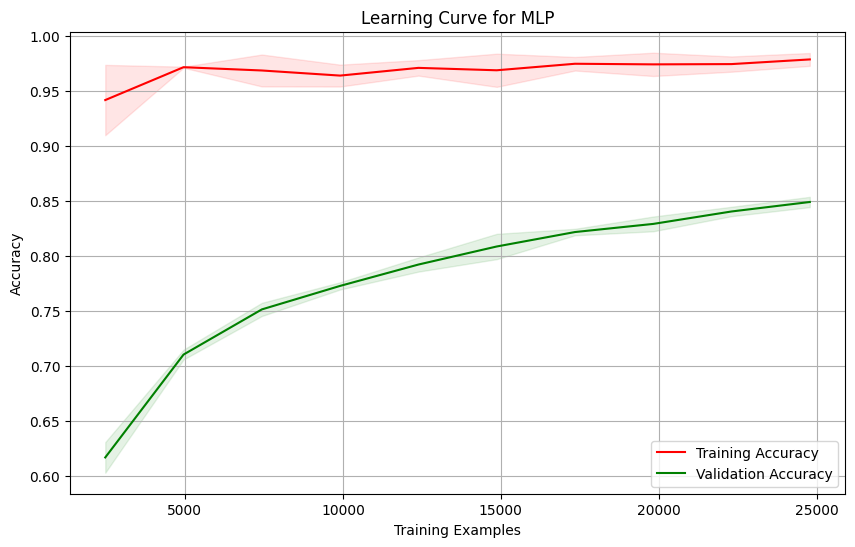

In [96]:
# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    mlp, X_train, y_train, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
)

# Mean and standard deviation for learning curves
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, '-', label="Training Accuracy", color="r")
plt.plot(train_sizes, test_mean, '-', label="Validation Accuracy", color="g")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color="g")
plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curve for MLP")
plt.legend(loc="best")
plt.grid()
plt.show() 

In [51]:
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


Classification Report:
              precision    recall  f1-score   support

       angry       0.87      0.86      0.87      1095
        calm       0.86      0.91      0.88      1070
     disgust       0.90      0.89      0.89      1061
     fearful       0.87      0.81      0.84      1010
       happy       0.91      0.89      0.90      1028
     neutral       0.89      0.79      0.84       495
         sad       0.81      0.92      0.86      1044
    surprise       0.80      0.79      0.79       942

    accuracy                           0.86      7745
   macro avg       0.86      0.86      0.86      7745
weighted avg       0.86      0.86      0.86      7745



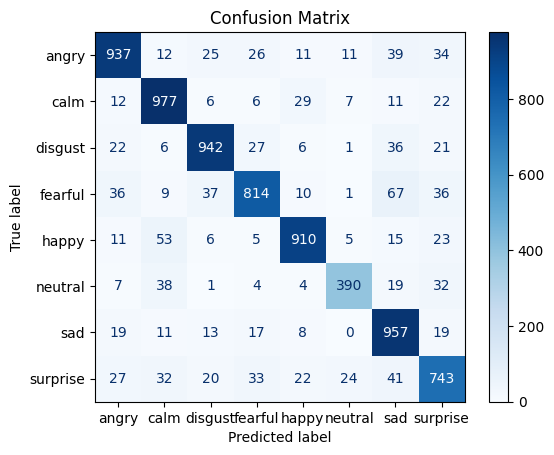

In [34]:
conf_matrix = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=mlp.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# Initialize Decision Tree with more aggressive pruning and constraints
dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=6,  # Reduce the maximum depth further
    min_samples_split=30,
    min_samples_leaf=20,
    ccp_alpha=0.0001,  # Increase pruning strength
    random_state=42
)

# Train Decision Tree
dt.fit(X_train, y_train)

# Prediction and probabilities for Decision Tree
y_train_pred_dt = dt.predict(X_train)
y_test_pred_dt = dt.predict(X_test)
y_train_pred_proba_dt = dt.predict_proba(X_train)
y_test_pred_proba_dt = dt.predict_proba(X_test)

# Decision Tree Metrics
print("Decision Tree Metrics:")
print("Training Accuracy:", accuracy_score(y_train, y_train_pred_dt))
print("F1 Score:", f1_score(y_train, y_train_pred_dt, average='weighted'))
print("Precision Score:", precision_score(y_train, y_train_pred_dt, average='weighted'))
print("Recall Score:", recall_score(y_train, y_train_pred_dt, average='weighted'))
print("ROC AUC Score:", roc_auc_score(y_train, y_train_pred_proba_dt, multi_class='ovr'))

print("Test Accuracy:", accuracy_score(y_test, y_test_pred_dt))
print("F1 Score:", f1_score(y_test, y_test_pred_dt, average='weighted'))
print("Precision Score:", precision_score(y_test, y_test_pred_dt, average='weighted'))
print("Recall Score:", recall_score(y_test, y_test_pred_dt, average='weighted'))
print("ROC AUC Score:", roc_auc_score(y_test, y_test_pred_proba_dt, multi_class='ovr'))



Decision Tree Metrics:
Training Accuracy: 0.3230888429752066
F1 Score: 0.3064273983126791
Precision Score: 0.4256686407699686
Recall Score: 0.3230888429752066
ROC AUC Score: 0.7175329653205973
Test Accuracy: 0.32033570045190446
F1 Score: 0.306994967738755
Precision Score: 0.42187332674110073
Recall Score: 0.32033570045190446
ROC AUC Score: 0.7069797768931368


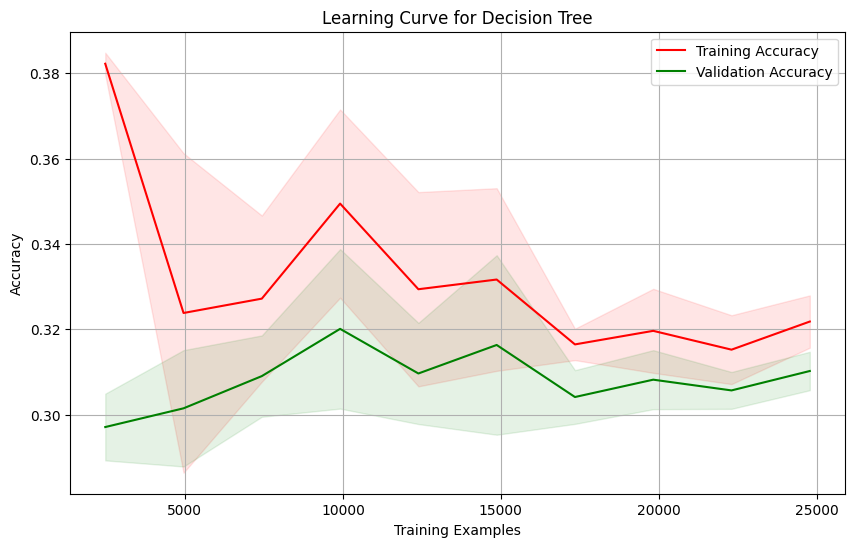

In [68]:
# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    dt, X_train, y_train, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
)

# Mean and standard deviation for learning curves
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, '-', label="Training Accuracy", color="r")
plt.plot(train_sizes, test_mean, '-', label="Validation Accuracy", color="g")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color="g")
plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curve for Decision Tree")
plt.legend(loc="best")
plt.grid()
plt.show()

In [72]:
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_dt))


Classification Report:
              precision    recall  f1-score   support

       angry       0.23      0.50      0.32      1095
        calm       0.26      0.55      0.35      1070
     disgust       0.54      0.38      0.44      1061
     fearful       0.27      0.37      0.31      1010
       happy       0.87      0.30      0.45      1028
     neutral       0.29      0.03      0.06       495
         sad       0.49      0.14      0.21      1044
    surprise       0.35      0.10      0.16       942

    accuracy                           0.32      7745
   macro avg       0.41      0.30      0.29      7745
weighted avg       0.42      0.32      0.31      7745



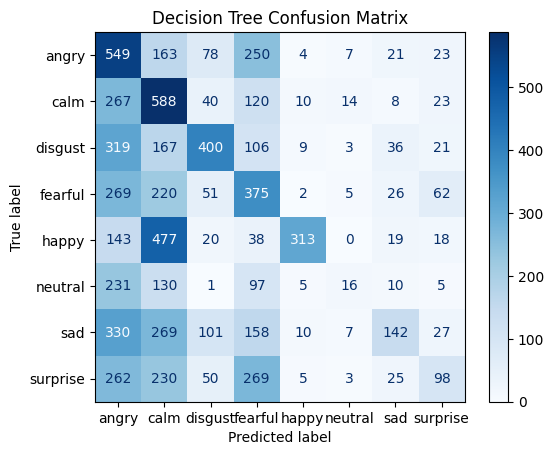

In [76]:
conf_matrix_dt = confusion_matrix(y_test, y_test_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_dt, display_labels=dt.classes_)
disp_dt.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, accuracy_score

# Define hyperparameter grid for Logistic Regression
param_grid = {
    'penalty': ['l2', 'elasticnet'],  # Regularization
    'C': [0.01, 0.1, 1, 10, 100],    # Inverse of regularization strength
    'solver': ['liblinear', 'saga'],  # Solvers for optimization
    'max_iter': [100, 200, 500]       # Maximum number of iterations
}

# Initialize Logistic Regression
logreg = LogisticRegression(multi_class='ovr')

# Set up GridSearchCV
grid_search = GridSearchCV(estimator=logreg, 
                           param_grid=param_grid, 
                           cv=5,                      # 5-fold cross-validation
                           scoring='accuracy',        # Scoring metric to optimize
                           n_jobs=-1,                  # Use all available CPU cores
                           verbose=1)

# Fit GridSearchCV on the training data
grid_search.fit(X_train, y_train)

# Get the best hyperparameters from GridSearchCV
best_params = grid_search.best_params_
print(f"Best Hyperparameters: {best_params}")

# Evaluate the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Train accuracy using best model
y_train_pred = best_model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)

# Test accuracy using best model
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

# Output results
print(f"Training Accuracy with tuned Logistic Regression: {train_accuracy:.4f}")
print(f"Test Accuracy with tuned Logistic Regression: {test_accuracy:.4f}")

# Optionally, print more metrics
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

# Training set metrics
train_f1 = f1_score(y_train, y_train_pred, average='weighted')
train_precision = precision_score(y_train, y_train_pred, average='weighted')
train_recall = recall_score(y_train, y_train_pred, average='weighted')
train_rocauc = roc_auc_score(y_train, best_model.predict_proba(X_train), multi_class='ovr')

# Test set metrics
test_f1 = f1_score(y_test, y_test_pred, average='weighted')
test_precision = precision_score(y_test, y_test_pred, average='weighted')
test_recall = recall_score(y_test, y_test_pred, average='weighted')
test_rocauc = roc_auc_score(y_test, best_model.predict_proba(X_test), multi_class='ovr')

print("\nTraining set performance:")
print(f"- F1 Score: {train_f1:.4f}")
print(f"- Precision: {train_precision:.4f}")
print(f"- Recall: {train_recall:.4f}")
print(f"- ROC AUC Score: {train_rocauc:.4f}")

print("\nTest set performance:")
print(f"- F1 Score: {test_f1:.4f}")
print(f"- Precision: {test_precision:.4f}")
print(f"- Recall: {test_recall:.4f}")
print(f"- ROC AUC Score: {test_rocauc:.4f}")


In [82]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# Initialize Random Forest with regularization parameters
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    bootstrap=True,
    class_weight='balanced',
    random_state=42
)

# Fit the model
rf.fit(X_train, y_train)

# Evaluation for Random Forest
y_train_pred_rf = rf.predict(X_train)
y_test_pred_rf = rf.predict(X_test)
y_train_pred_proba_rf = rf.predict_proba(X_train)
y_test_pred_proba_rf = rf.predict_proba(X_test)

# Random Forest Metrics
print("Random Forest Metrics after hyparameter tuning:")
print("Training Accuracy:", accuracy_score(y_train, y_train_pred_rf))
print("F1 Score:", f1_score(y_train, y_train_pred_rf, average='weighted'))
print("Precision Score:", precision_score(y_train, y_train_pred_rf, average='weighted'))
print("Recall Score:", recall_score(y_train, y_train_pred_rf, average='weighted'))
print("ROC AUC Score:", roc_auc_score(y_train, y_train_pred_proba_rf, multi_class='ovr'))
print("="*35)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred_rf))
print("F1 Score:", f1_score(y_test, y_test_pred_rf, average='weighted'))
print("Precision Score:", precision_score(y_test, y_test_pred_rf, average='weighted'))
print("Recall Score:", recall_score(y_test, y_test_pred_rf, average='weighted'))
print("-ROC AUC Score:", roc_auc_score(y_test, y_test_pred_proba_rf, multi_class='ovr'))


Random Forest Metrics after hyparameter tuning:
Training Accuracy: 0.6813339359504132
F1 Score: 0.6828016268911559
Precision Score: 0.713124815106711
Recall Score: 0.6813339359504132
ROC AUC Score: 0.9372905592269696
Test Accuracy: 0.6116204002582312
F1 Score: 0.6094534440339017
Precision Score: 0.6416506464187844
Recall Score: 0.6116204002582312
-ROC AUC Score: 0.9103825494235649


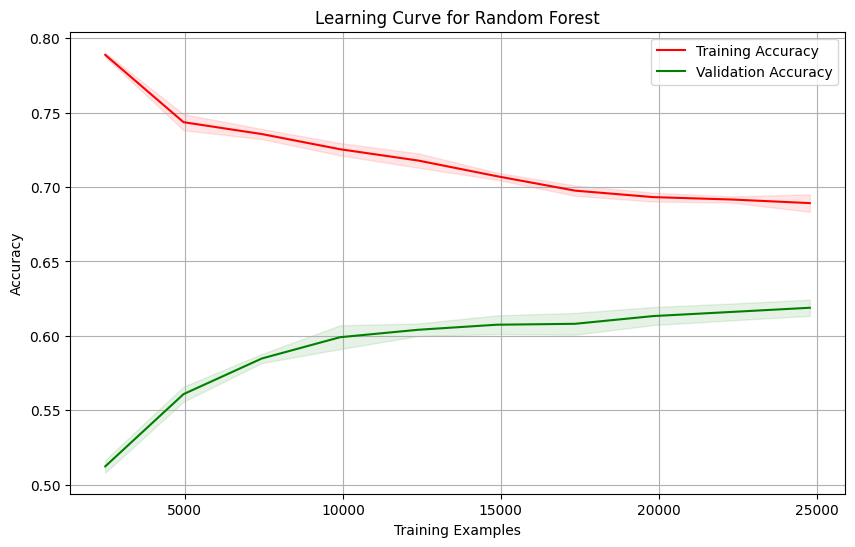

In [92]:
# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    rf, X_train, y_train, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
)

# Mean and standard deviation for learning curves
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, '-', label="Training Accuracy", color="r")
plt.plot(train_sizes, test_mean, '-', label="Validation Accuracy", color="g")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color="g")
plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curve for Random Forest")
plt.legend(loc="best")
plt.grid()
plt.show()

In [84]:
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))


Classification Report:
              precision    recall  f1-score   support

       angry       0.61      0.52      0.56      1095
        calm       0.54      0.68      0.60      1070
     disgust       0.59      0.75      0.66      1061
     fearful       0.68      0.56      0.62      1010
       happy       0.81      0.73      0.77      1028
     neutral       0.41      0.88      0.56       495
         sad       0.67      0.50      0.57      1044
    surprise       0.71      0.39      0.50       942

    accuracy                           0.61      7745
   macro avg       0.63      0.63      0.61      7745
weighted avg       0.64      0.61      0.61      7745



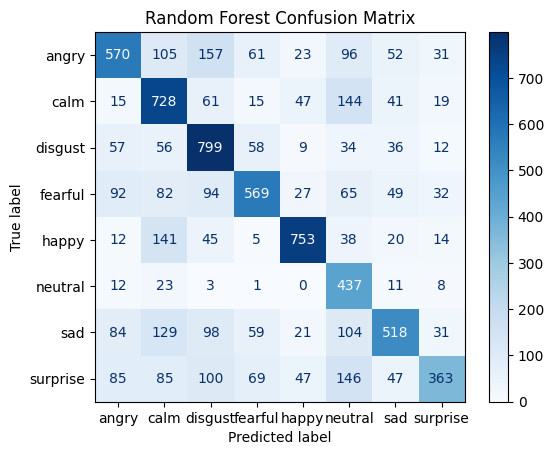

In [90]:
conf_matrix_dt = confusion_matrix(y_test, y_test_pred_rf)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_dt, display_labels=dt.classes_)
disp_dt.plot(cmap=plt.cm.Blues)
plt.title("Random Forest Confusion Matrix")
plt.show()
